# Building Candidates for warehouses

This notebook builds the pool of candidate buildings. 
- 1,858 m² cutoff for candidates (equal to 20,000 sq ft)
- 4,645 m² threshold for `is_large` (equal to 50,000 sq ft, the EDF report's warehouse size)

### Libraries

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import from_bounds

# Repo root: the first folder above this notebook that contains data/data_sources.txt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "data_sources.txt").exists())
RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"
NAIP_DIR = Path("/Volumes/Storage/naip")  # external USB drive

MIN_M2 = 1_858     # candidate cutoff (= 20,000 sq ft)
LARGE_M2 = 4_645   # EDF report's large-warehouse threshold (= 50,000 sq ft)
UTM = "EPSG:26918" # NAIP tiles are in UTM zone 18N (NAD83), metres

### NAIP tiles
The tile index lists every NAIP tile that covers the study area; keep only the years actually downloaded to the USB drive.

In [2]:
assert NAIP_DIR.exists(), f"{NAIP_DIR} not found; plug in the USB drive"

naip = gpd.read_file(NAIP_DIR / "naip_index.geojson")
naip["downloaded"] = naip["path"].map(lambda p: (NAIP_DIR / p).exists())
naip = naip[naip["downloaded"]].to_crs(UTM)
NAIP_YEARS = sorted(naip["year"].unique())

naip.groupby("year").agg(tiles=("id", "size"), resolution_m=("gsd", "first"))

,tiles,resolution_m
year,,
2010,64,1.0
2015,64,1.0
2019,64,0.6
2022,64,0.6


### Find Candidates

- Microsoft footprints primary
- OSM secondary - catches what Microsoft does not

In [3]:
where = f"area_m2 >= {MIN_M2}"
ms = gpd.read_file(RAW / "ms_buildings" / "ms_buildings_core.gpkg", layer="buildings", where=where)
osm = gpd.read_file(RAW / "osm" / "osm_core.gpkg", layer="buildings", where=where)
ms, osm = ms.to_crs(UTM), osm.to_crs(UTM)

osm_only = osm[~osm.index.isin(gpd.sjoin(osm, ms, predicate="intersects").index)]

candidates = pd.concat([
    ms[["area_m2", "geometry"]].assign(source="microsoft"),
    osm_only[["area_m2", "geometry"]].assign(source="osm"),
], ignore_index=True)
candidates = gpd.GeoDataFrame(candidates, crs=UTM)
candidates.insert(0, "cand_id", [f"c{i:05d}" for i in range(len(candidates))])
candidates["is_large"] = candidates["area_m2"] >= LARGE_M2

print(f"Microsoft >= {MIN_M2:,} m2: {len(ms):,}")
print(f"OSM-only additions: {len(osm_only):,}")
print(f"Candidates: {len(candidates):,} ({candidates['is_large'].sum():,} >= {LARGE_M2:,} m2)")

Microsoft >= 1,858 m2: 6,346
OSM-only additions: 476
Candidates: 6,822 (2,563 >= 4,645 m2)


### Add context: OSM tags, parcel class, county
Each candidate gets the OSM building type and the tax parcel it sits on (matched at a point inside the roof). Parcel class `4B` is industrial, `4A` commercial

In [4]:
points = candidates[["cand_id", "geometry"]].copy()
points["geometry"] = candidates.representative_point()

osm_all = gpd.read_file(RAW / "osm" / "osm_core.gpkg", layer="buildings",
                        columns=["building", "name"], where="area_m2 >= 500").to_crs(UTM)
parcels = gpd.read_file(RAW / "parcels" / "parcels_core.gpkg", layer="parcels",
                        columns=["MUN_NAME", "PROP_CLASS", "BLDG_DESC", "FAC_NAME", "YR_CONSTR"]).to_crs(UTM)
counties = gpd.read_file(RAW / "core_counties.geojson", columns=["NAME"]).to_crs(UTM)


def first_match(right, cols):
    # Attributes of the polygon each candidate's roof point falls in (first match if several).
    joined = gpd.sjoin(points, right[cols + ["geometry"]], predicate="within", how="left")
    return joined.drop_duplicates("cand_id").set_index("cand_id")[cols]


context = pd.concat([
    first_match(osm_all, ["building", "name"]).rename(columns={"building": "osm_building", "name": "osm_name"}),
    first_match(parcels, ["MUN_NAME", "PROP_CLASS", "BLDG_DESC", "FAC_NAME", "YR_CONSTR"]),
    first_match(counties, ["NAME"]).rename(columns={"NAME": "county"}),
], axis=1)
context.columns = [c.lower() for c in context.columns]
candidates = candidates.merge(context, left_on="cand_id", right_index=True, how="left")

candidates["warehouse_hint"] = (candidates["osm_building"].isin(["warehouse", "industrial"])
                                | (candidates["prop_class"] == "4B"))
print(candidates["prop_class"].fillna("other").value_counts().to_string())
print(f"warehouse_hint: {candidates['warehouse_hint'].sum():,} of {len(candidates):,}")

prop_class
4B       2656
other    2538
4A       1628
warehouse_hint: 2,883 of 6,822


### Link candidates to NAIP tiles
For each downloaded year, `naip_<year>` is the tile containing the building's centre. `spans_tiles` marks buildings that cross a tile edge; their chips will need both tiles.

In [5]:
centroids = candidates[["cand_id"]].join(candidates.centroid.rename("geometry")).set_geometry("geometry")

primary = gpd.sjoin(centroids, naip[["year", "path", "geometry"]], predicate="within")
primary = primary.drop_duplicates(["cand_id", "year"])
paths = primary.pivot(index="cand_id", columns="year", values="path").add_prefix("naip_")

touching = gpd.sjoin(candidates[["cand_id", "geometry"]], naip[["year", "geometry"]], predicate="intersects")
spans = touching.groupby(["cand_id", "year"]).size().groupby("cand_id").max().gt(1).rename("spans_tiles")

candidates = candidates.drop(columns=[c for c in candidates if str(c).startswith("naip_")], errors="ignore")
candidates = candidates.merge(paths, left_on="cand_id", right_index=True, how="left")
candidates = candidates.merge(spans, left_on="cand_id", right_index=True, how="left")

naip_cols = [f"naip_{y}" for y in NAIP_YEARS]
print("Candidates with a tile, by year:")
print(candidates[naip_cols].notna().sum().to_string())
print(f"spans_tiles: {candidates['spans_tiles'].sum():,}")

Candidates with a tile, by year:
naip_2010    6822
naip_2015    6822
naip_2019    6822
naip_2022    6822
spans_tiles: 1,599


### Summary

In [6]:
pd.crosstab(candidates["county"].fillna("outside"), candidates["warehouse_hint"],
            margins=True).rename(columns={False: "other", True: "warehouse_hint"})

warehouse_hint,other,warehouse_hint,All
county,,,
Essex,1429,665,2094
Middlesex,1577,1554,3131
Union,930,664,1594
outside,3,0,3
All,3939,2883,6822


### Preview
One candidate with a warehouse hint on the 2022 imagery (60 cm), with its footprint outlined, to check that buildings and imagery line up.

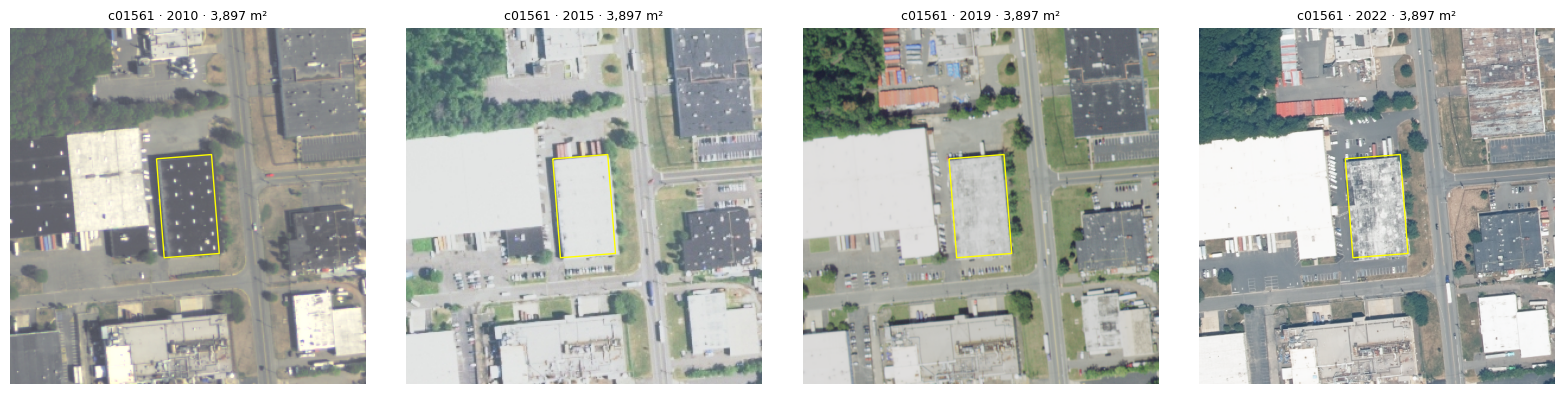

In [7]:
def show_candidate(row, year, size_m=300, ax=None):
    # Plot the NAIP RGB around a candidate with its footprint outlined.
    cx, cy = row.geometry.centroid.x, row.geometry.centroid.y
    half = size_m / 2
    with rasterio.open(NAIP_DIR / row[f"naip_{year}"]) as src:
        window = from_bounds(cx - half, cy - half, cx + half, cy + half, src.transform)
        rgb = src.read([1, 2, 3], window=window, boundless=True, fill_value=0)
    ax = ax or plt.subplots(figsize=(5, 5))[1]
    ax.imshow(np.moveaxis(rgb, 0, -1), extent=(cx - half, cx + half, cy - half, cy + half))
    gpd.GeoSeries([row.geometry], crs=UTM).boundary.plot(ax=ax, color="yellow", linewidth=1)
    ax.set_title(f"{row.cand_id} · {year} · {row.area_m2:,.0f} m²", fontsize=9)
    ax.set_axis_off()
    return ax


example = candidates[candidates["warehouse_hint"] & candidates["naip_2022"].notna()].sample(1, random_state=0).iloc[0]
fig, axes = plt.subplots(1, len(NAIP_YEARS), figsize=(4 * len(NAIP_YEARS), 4))
for ax, year in zip(axes, NAIP_YEARS):
    if pd.notna(example[f"naip_{year}"]):
        show_candidate(example, year, ax=ax)
plt.tight_layout()

### Save

In [8]:
INTERIM.mkdir(parents=True, exist_ok=True)
out = INTERIM / "warehouse_candidates.gpkg"
candidates.to_file(out, layer="candidates", driver="GPKG")
print(f"Saved {len(candidates):,} candidates to {out.relative_to(ROOT)}")